# Full Precision Neural Network from scratch

In [ ]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

In [ ]:
mnist = fetch_openml('mnist_784', version=1)
X = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(int)

In [ ]:
print(f"Total number of images in the MNIST dataset: {X.shape[0]}")

Total number of images in the MNIST dataset: 70000


In [ ]:
# One-hot encode labels
encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y.to_numpy().reshape(-1, 1))

# First split: 90% for training+validation, 10% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y_onehot, test_size=0.1, random_state=42
)

# Second split: From the training+validation set, take 1/9 (approx 11.11%) for validation
# (0.1 / (1 - 0.1) = 0.1 / 0.9 = 1/9) to get 10% of the original dataset for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1 / 0.9, random_state=42
)

print(f"Training set size: {len(X_train)} samples")
print(f"Validation set size: {len(X_val)} samples")
print(f"Test set size: {len(X_test)} samples")

Training set size: 55999 samples
Validation set size: 7001 samples
Test set size: 7000 samples


In [ ]:
class LayerDense:
  #Layer initialization
  def __init__(self, n_inputs, n_neurons):
    self.weights = 0.01* np.random.randn(n_inputs, n_neurons)
    self.biases = np.zeros((1, n_neurons))

  #forward pass
  def forward(self, inputs):
    self.inputs = inputs
    self.output = np.dot(inputs, self.weights) + self.biases

  #backward pass
  def backward(self, dvalues):
    self.dweights = np.dot(self.inputs.T, dvalues)
    self.dbiases = np.sum(dvalues, axis=0, keepdims=True)
    self.dinputs = np.dot(dvalues, self.weights.T)

In [ ]:
class Activation_Relu:
  #Forward Pass
  def forward(self, inputs):
    self.inputs = inputs
    self.output = np.maximum(0, inputs)

  #backward pass
  def backward(self, dvalues):
    #we are going to modify the original variable so make a copy
    self.dinputs = dvalues.copy()
    self.dinputs[self.inputs<=0]=0

In [ ]:
class Activation_Softmax:
  #forward pass
  def forward(self, inputs):
    #unnormalized values
    exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True)) # max values are subtracted from each inputs to ensure that the values don't overflow
    #Normalize them for each sample
    probabilities = exp_values/ np.sum(exp_values, axis=1, keepdims=True)
    self.output = probabilities

  #backward pass
  #For backward pass we are going to combine it with loss for the ease of calculation

In [ ]:
class Loss:
  def calculate(self, output, y):
    sample_losses = self.forward(output, y)
    data_loss = np.mean(sample_losses)
    return data_loss

In [ ]:
class Loss_CategoricalCrossEntropy(Loss):
  #forward pass
  def forward(self, y_pred, y_true):
    samples = len(y_pred)

    #clip data to prevent division by 0
    #clip both sides to not drag mean towards any value
    y_pred_clipped = np.clip(y_pred, 1e-7, 1-1e-7)

    #probabilities for target values
    #only if categorical labels
    if len(y_true.shape)==1:
      correct_confidences = y_pred_clipped[range(samples), y_true]

    #mask values- only for one hot encoded labels
    elif len(y_true.shape)==2:
      correct_confidences = np.sum(y_pred_clipped*y_true, axis=1)

    #losses
    negative_log_likelihood = -np.log(correct_confidences)
    return negative_log_likelihood


In [ ]:
#Softmax classifier - combined softmax activation and cross-entropy loss for faster backward step

class Activation_Softmax_Loss_CategoricalCrossentropy:
  #creates activation and loss function objects
  def __init__(self):
    self.activation = Activation_Softmax()
    self.loss = Loss_CategoricalCrossEntropy()

  #forward pass
  def forward(self, inputs, y_true):
    #output layers activation function
    self.activation.forward(inputs)
    #set the output
    self.output = self.activation.output
    #calculate and return loss values
    return self.loss.calculate(self.output, y_true)

  #backward pass
  def backward(self, dvalues, y_true):
    samples = len(dvalues)

    if(len(y_true.shape)==2):
      y_true = np.argmax(y_true, axis=1)
      #copy the original values

      self.dinputs = dvalues.copy()
      #calculate the gradients
      self.dinputs[range(samples), y_true] -= 1
      #Normalize gradients
      self.dinputs = self.dinputs/samples


In [ ]:
import numpy as np

# Adam optimizer
class Optimizer_Adam:
    # Initialize optimizer - set settings
    def __init__(self, learning_rate=0.001, decay=0., epsilon=1e-7, beta_1=0.9, beta_2=0.999):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.beta_1 = beta_1
        self.beta_2 = beta_2

    # Call once before any parameter updates
    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):
        # If layer does not contain cache arrays, create them filled with zeros
        if not hasattr(layer, 'weight_cache'):
            layer.weight_momentums = np.zeros_like(layer.weights)
            layer.weight_cache = np.zeros_like(layer.weights)
            layer.bias_momentums = np.zeros_like(layer.biases)
            layer.bias_cache = np.zeros_like(layer.biases)

        # Update momentum with current gradients
        layer.weight_momentums = self.beta_1 * layer.weight_momentums + (1 - self.beta_1) * layer.dweights
        layer.bias_momentums = self.beta_1 * layer.bias_momentums + (1 - self.beta_1) * layer.dbiases

        # Get corrected momentum
        # self.iteration is 0 at first pass and we need to start with 1 here
        weight_momentums_corrected = layer.weight_momentums / (1 - self.beta_1 ** (self.iterations + 1))
        bias_momentums_corrected = layer.bias_momentums / (1 - self.beta_1 ** (self.iterations + 1))

        # Update cache with squared current gradients
        layer.weight_cache = self.beta_2 * layer.weight_cache + (1 - self.beta_2) * layer.dweights**2
        layer.bias_cache = self.beta_2 * layer.bias_cache + (1 - self.beta_2) * layer.dbiases**2

        # Get corrected cache
        weight_cache_corrected = layer.weight_cache / (1 - self.beta_2 ** (self.iterations + 1))
        bias_cache_corrected = layer.bias_cache / (1 - self.beta_2 ** (self.iterations + 1))

        # Vanilla SGD parameter update + normalization with square rooted cache
        layer.weights += -self.current_learning_rate * weight_momentums_corrected / (np.sqrt(weight_cache_corrected) + self.epsilon)
        layer.biases += -self.current_learning_rate * bias_momentums_corrected / (np.sqrt(bias_cache_corrected) + self.epsilon)

    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1

In [ ]:
dense1 = LayerDense(784,128)
activation1 = Activation_Relu()
dense2 = LayerDense(128,64)
activation2 = Activation_Relu()
dense3 = LayerDense(64,10)
activation3 = Activation_Softmax_Loss_CategoricalCrossentropy()

optimizer = Optimizer_Adam(learning_rate=0.001, decay=1e-5)

# Number of epochs
epochs = 9
# Batch size
batch_size = 128
# Number of training samples
n_samples = len(X_train)
# Number of batches
n_batches = n_samples // batch_size

# Lists to store metrics for plotting
training_losses = []
training_accuracies = []
val_losses = [] # Changed from test_losses
val_accuracies = [] # Changed from test_accuracies

for epoch in range(epochs):
  # Shuffle data at the beginning of each epoch
  permutation = np.random.permutation(n_samples)
  # Ensure X_train_shuffled and y_train_shuffled are consistent
  # If X_train is a DataFrame, use .iloc for integer-location based indexing
  X_train_shuffled = X_train.iloc[permutation]
  y_train_shuffled = y_train[permutation]

  epoch_loss = 0
  epoch_accuracy = 0

  for i in range(n_batches):
    # Get batch data
    batch_start = i * batch_size
    batch_end = (i + 1) * batch_size
    X_batch = X_train_shuffled[batch_start:batch_end]
    y_batch = y_train_shuffled[batch_start:batch_end]

    # Forward pass
    dense1.forward(X_batch)
    activation1.forward(dense1.output)

    dense2.forward(activation1.output)
    activation2.forward(dense2.output)

    dense3.forward(activation2.output)

    loss = activation3.forward(dense3.output, y_batch)
    epoch_loss += loss

    # Calculate accuracy
    predictions = np.argmax(activation3.output, axis=1)
    y_true_batch = np.argmax(y_batch, axis=1)
    accuracy = np.mean(predictions == y_true_batch)
    epoch_accuracy += accuracy

    # Backward pass
    activation3.backward(activation3.output, y_batch)
    dense3.backward(activation3.dinputs)

    activation2.backward(dense3.dinputs)
    dense2.backward(activation2.dinputs)

    activation1.backward(dense2.dinputs)
    dense1.backward(activation1.dinputs)

    # Update parameters
    optimizer.pre_update_params()
    optimizer.update_params(dense1)
    optimizer.update_params(dense2)
    optimizer.update_params(dense3)
    optimizer.post_update_params()

  # Calculate average loss and accuracy for the epoch
  epoch_loss /= n_batches
  epoch_accuracy /= n_batches

  # Evaluate on validation set after each epoch (changed from test set)
  dense1.forward(X_val)
  activation1.forward(dense1.output)
  dense2.forward(activation1.output)
  activation2.forward(dense2.output)
  dense3.forward(activation2.output)
  val_loss = activation3.forward(dense3.output, y_val)
  val_predictions = np.argmax(activation3.output, axis=1)
  val_y_true = np.argmax(y_val, axis=1)
  val_accuracy = np.mean(val_predictions == val_y_true)

  # Store metrics
  training_losses.append(epoch_loss)
  training_accuracies.append(epoch_accuracy)
  val_losses.append(val_loss)
  val_accuracies.append(val_accuracy)

  print(f'epoch: {epoch}, ' +
        f'acc: {epoch_accuracy:.3f}, ' +
        f'loss: {epoch_loss:.3f}, ' +
        f'val_acc: {val_accuracy:.3f}, ' +
        f'val_loss: {val_loss:.3f}, ' +
        f'lr: {optimizer.current_learning_rate}')

# --- Final evaluation on the test set after all epochs ---
print("\n--- Final Evaluation on Test Set ---")
dense1.forward(X_test)
activation1.forward(dense1.output)
dense2.forward(activation1.output)
activation2.forward(dense2.output)
dense3.forward(activation2.output)
final_test_loss = activation3.forward(dense3.output, y_test)
final_test_predictions = np.argmax(activation3.output, axis=1)
final_test_y_true = np.argmax(y_test, axis=1)
final_test_accuracy = np.mean(final_test_predictions == final_test_y_true)

print(f'Final Test Accuracy: {final_test_accuracy:.3f}, Final Test Loss: {final_test_loss:.3f}')

epoch: 0, acc: 0.814, loss: 0.620, val_acc: 0.911, val_loss: 0.315, lr: 0.0009956589270779402
epoch: 1, acc: 0.922, loss: 0.268, val_acc: 0.943, val_loss: 0.203, lr: 0.0009913455533195207
epoch: 2, acc: 0.945, loss: 0.188, val_acc: 0.952, val_loss: 0.165, lr: 0.0009870693909781857
epoch: 3, acc: 0.958, loss: 0.143, val_acc: 0.964, val_loss: 0.119, lr: 0.0009828299605885184
epoch: 4, acc: 0.966, loss: 0.114, val_acc: 0.968, val_loss: 0.105, lr: 0.0009786267908870271
epoch: 5, acc: 0.973, loss: 0.092, val_acc: 0.973, val_loss: 0.089, lr: 0.0009744594186375107
epoch: 6, acc: 0.977, loss: 0.075, val_acc: 0.974, val_loss: 0.084, lr: 0.0009703273884608667
epoch: 7, acc: 0.981, loss: 0.063, val_acc: 0.977, val_loss: 0.074, lr: 0.0009662302526692111
epoch: 8, acc: 0.984, loss: 0.053, val_acc: 0.975, val_loss: 0.078, lr: 0.0009621675711041835

--- Final Evaluation on Test Set ---
Final Test Accuracy: 0.971, Final Test Loss: 0.102


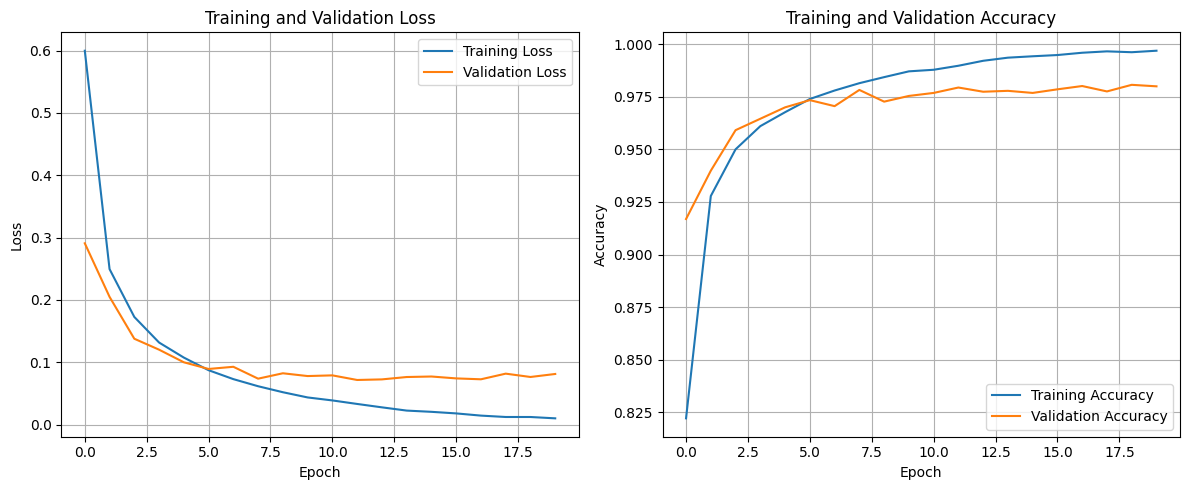

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(epochs)

plt.figure(figsize=(12, 5))

# Plot Training & Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, training_losses, label='Training Loss')
plt.plot(epochs_range, val_losses, label='Validation Loss') # Changed from test_losses
plt.title('Training and Validation Loss') # Changed title
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Training & Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, training_accuracies, label='Training Accuracy')
plt.plot(epochs_range, val_accuracies, label='Validation Accuracy') # Changed from test_accuracies
plt.title('Training and Validation Accuracy') # Changed title
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Full precision neural network using Torch

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
batch_size = 64
learning_rate = 1e-3
epochs = 8

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_dataset = datasets.MNIST(root="./data", train=True, transform=transform, download=True)

# split into train + validation
train_size = int(0.9 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

test_dataset = datasets.MNIST(root="./data", train=False, transform=transform, download=True)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)  # flatten (B, 1, 28, 28) → (B, 784)
        return self.model(x)

model = MLP().to(device)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
train_losses, val_losses = [], []
train_accs, val_accs = [], []

In [ ]:
for epoch in range(epochs):
    # ---- TRAIN ----
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(train_loader)
    train_acc = correct / total

    # ---- VALIDATION ----
    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    val_loss /= len(val_loader)
    val_acc = correct / total

    # store
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}: "
          f"Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f} | "
          f"Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}")

Epoch 1: Train Loss=0.4194, Train Acc=0.8753 | Val Loss=0.2771, Val Acc=0.9172
Epoch 2: Train Loss=0.2026, Train Acc=0.9392 | Val Loss=0.1686, Val Acc=0.9483
Epoch 3: Train Loss=0.1441, Train Acc=0.9552 | Val Loss=0.1383, Val Acc=0.9588
Epoch 4: Train Loss=0.1142, Train Acc=0.9652 | Val Loss=0.1207, Val Acc=0.9642
Epoch 5: Train Loss=0.1014, Train Acc=0.9683 | Val Loss=0.1507, Val Acc=0.9525
Epoch 6: Train Loss=0.0872, Train Acc=0.9729 | Val Loss=0.1105, Val Acc=0.9657
Epoch 7: Train Loss=0.0764, Train Acc=0.9755 | Val Loss=0.1163, Val Acc=0.9662
Epoch 8: Train Loss=0.0680, Train Acc=0.9786 | Val Loss=0.1462, Val Acc=0.9588


In [ ]:
model.eval()
test_loss = 0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

test_loss /= len(test_loader)
test_acc = correct / total

print(f"\nTest Loss={test_loss:.4f}, Test Accuracy={test_acc:.4f}")


Test Loss=0.1233, Test Accuracy=0.9630


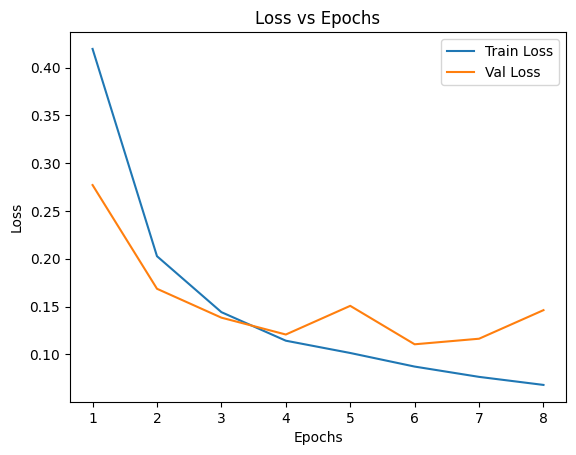

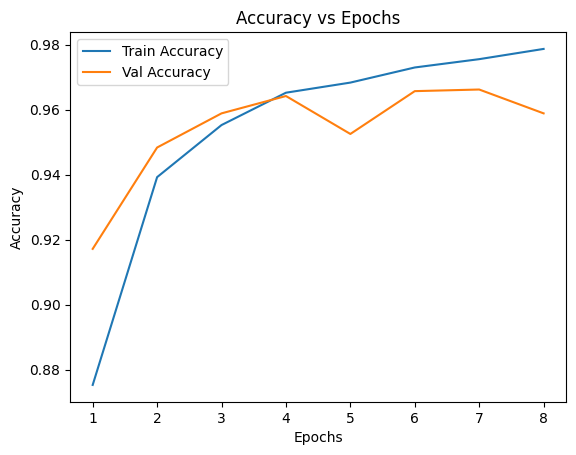

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

# Loss plot
plt.figure()
plt.plot(epochs_range, train_losses, label="Train Loss")
plt.plot(epochs_range, val_losses, label="Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss vs Epochs")
plt.legend()
plt.show()

# Accuracy plot
plt.figure()
plt.plot(epochs_range, train_accs, label="Train Accuracy")
plt.plot(epochs_range, val_accs, label="Val Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epochs")
plt.legend()
plt.show()

# Binary Neural Network from scratch

In [ ]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

In [ ]:
mnist = fetch_openml('mnist_784', version=1)
X = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(int)

In [ ]:
print(f"Total number of images in the MNIST dataset: {X.shape[0]}")

Total number of images in the MNIST dataset: 70000


In [ ]:
# One-hot encode labels
encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y.to_numpy().reshape(-1, 1))

# First split: 90% for training+validation, 10% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y_onehot, test_size=0.1, random_state=42
)

# Second split: From the training+validation set, take 1/9 (approx 11.11%) for validation
# (0.1 / (1 - 0.1) = 0.1 / 0.9 = 1/9) to get 10% of the original dataset for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1 / 0.9, random_state=42
)

print(f"Training set size: {len(X_train)} samples")
print(f"Validation set size: {len(X_val)} samples")
print(f"Test set size: {len(X_test)} samples")

Training set size: 55999 samples
Validation set size: 7001 samples
Test set size: 7000 samples


In [ ]:
#For 1 bit
# def clip(weights):
#   average = np.mean(weights)

#   weights -= average
#   return np.where(weights > 0, 1, -1)

#for 1.58 bit (This leads to aggressive prunning)
# def clip(weights):
#   average = np.mean(weights)

#   weights -= average
#   return np.where(weights > 0, 1,np.where(weights<0, -1, 0))

#For 1.58 bit (for proper quantization)
def clip(weights):
  delta = 0.05 * np.mean(np.abs(weights))  # threshold

  return np.where(weights > delta, 1,
          np.where(weights < -delta, -1, 0))

In [ ]:
class BinaryDenseLayer:
  def __init__(self, n_inputs, n_neurons):
    self.weights = np.random.randn(n_inputs, n_neurons)
    self.biases= np.zeros((1, n_neurons))
    self.weights_q = clip(self.weights)
    self.biases_q = clip(self.biases)

  def forward(self, inputs):
    self.inputs = inputs
    self.output = np.dot(inputs, self.weights_q) + self.biases_q

  def backward(self, dvalues):
    self.dweights = np.dot(self.inputs.T, dvalues)
    self.dbiases = np.sum(dvalues, axis=0, keepdims=True)
    self.dinputs = np.dot(dvalues, self.weights.T)

# class LayerDense:
#   #Layer initialization
#   def __init__(self, n_inputs, n_neurons):
#     self.weights = 0.01* np.random.randn(n_inputs, n_neurons)
#     self.biases = np.zeros((1, n_neurons))

#   #forward pass
#   def forward(self, inputs):
#     self.inputs = inputs
#     self.output = np.dot(inputs, self.weights) + self.biases

#   #backward pass
#   def backward(self, dvalues):
#     self.dweights = np.dot(self.inputs.T, dvalues)
#     self.dbiases = np.sum(dvalues, axis=0, keepdims=True)
#     self.dinputs = np.dot(dvalues, self.weights.T)


In [ ]:
class Activation_Relu:
  #Forward Pass
  def forward(self, inputs):
    self.inputs = inputs
    self.output = np.maximum(0, inputs)

  #backward pass
  def backward(self, dvalues):
    #we are going to modify the original variable so make a copy
    self.dinputs = dvalues.copy()
    self.dinputs[self.inputs<=0]=0

In [ ]:
class Activation_Softmax:
  #forward pass
  def forward(self, inputs):
    #unnormalized values
    exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True)) # max values are subtracted from each inputs to ensure that the values don't overflow
    #Normalize them for each sample
    probabilities = exp_values/ np.sum(exp_values, axis=1, keepdims=True)
    self.output = probabilities

  #backward pass
  #For backward pass we are going to combine it with loss for the ease of calculation

In [ ]:
class Loss:
  def calculate(self, output, y):
    sample_losses = self.forward(output, y)
    data_loss = np.mean(sample_losses)
    return data_loss

In [ ]:
class Loss_CategoricalCrossEntropy(Loss):
  #forward pass
  def forward(self, y_pred, y_true):
    samples = len(y_pred)

    #clip data to prevent division by 0
    #clip both sides to not drag mean towards any value
    y_pred_clipped = np.clip(y_pred, 1e-7, 1-1e-7)

    #probabilities for target values
    #only if categorical labels
    if len(y_true.shape)==1:
      correct_confidences = y_pred_clipped[range(samples), y_true]

    #mask values- only for one hot encoded labels
    elif len(y_true.shape)==2:
      correct_confidences = np.sum(y_pred_clipped*y_true, axis=1)

    #losses
    negative_log_likelihood = -np.log(correct_confidences)
    return negative_log_likelihood

In [ ]:
#Softmax classifier - combined softmax activation and cross-entropy loss for faster backward step

class Activation_Softmax_Loss_CategoricalCrossentropy:
  #creates activation and loss function objects
  def __init__(self):
    self.activation = Activation_Softmax()
    self.loss = Loss_CategoricalCrossEntropy()

  #forward pass
  def forward(self, inputs, y_true):
    #output layers activation function
    self.activation.forward(inputs)
    #set the output
    self.output = self.activation.output
    #calculate and return loss values
    return self.loss.calculate(self.output, y_true)

  #backward pass
  def backward(self, dvalues, y_true):
    samples = len(dvalues)

    if(len(y_true.shape)==2):
      y_true = np.argmax(y_true, axis=1)
      #copy the original values

      self.dinputs = dvalues.copy()
      #calculate the gradients
      self.dinputs[range(samples), y_true] -= 1
      #Normalize gradients
      self.dinputs = self.dinputs/samples

In [ ]:
# Adam optimizer
class Optimizer_Adam:
    # Initialize optimizer - set settings
    def __init__(self, learning_rate=0.0005, decay=0., epsilon=1e-7, beta_1=0.9, beta_2=0.999):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.beta_1 = beta_1
        self.beta_2 = beta_2

    # Call once before any parameter updates
    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):
        # If layer does not contain cache arrays, create them filled with zeros
        if not hasattr(layer, 'weight_cache'):
            layer.weight_momentums = np.zeros_like(layer.weights)
            layer.weight_cache = np.zeros_like(layer.weights)
            layer.bias_momentums = np.zeros_like(layer.biases)
            layer.bias_cache = np.zeros_like(layer.biases)

        # Update momentum with current gradients
        layer.weight_momentums = self.beta_1 * layer.weight_momentums + (1 - self.beta_1) * layer.dweights
        layer.bias_momentums = self.beta_1 * layer.bias_momentums + (1 - self.beta_1) * layer.dbiases

        # Get corrected momentum
        # self.iteration is 0 at first pass and we need to start with 1 here
        weight_momentums_corrected = layer.weight_momentums / (1 - self.beta_1 ** (self.iterations + 1))
        bias_momentums_corrected = layer.bias_momentums / (1 - self.beta_1 ** (self.iterations + 1))

        # Update cache with squared current gradients
        layer.weight_cache = self.beta_2 * layer.weight_cache + (1 - self.beta_2) * layer.dweights**2
        layer.bias_cache = self.beta_2 * layer.bias_cache + (1 - self.beta_2) * layer.dbiases**2

        # Get corrected cache
        weight_cache_corrected = layer.weight_cache / (1 - self.beta_2 ** (self.iterations + 1))
        bias_cache_corrected = layer.bias_cache / (1 - self.beta_2 ** (self.iterations + 1))

        # Vanilla SGD parameter update + normalization with square rooted cache
        layer.weights += -self.current_learning_rate * weight_momentums_corrected / (np.sqrt(weight_cache_corrected) + self.epsilon)
        layer.weights_q = clip(layer.weights)
        layer.biases += -self.current_learning_rate * bias_momentums_corrected / (np.sqrt(bias_cache_corrected) + self.epsilon)
        layer.biases_q = clip(layer.biases)

    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1

In [ ]:
# dense1 = BinaryDenseLayer(784,128)
# activation1 = Activation_Relu()
# dense2 = BinaryDenseLayer(128,64)
# activation2 = Activation_Relu()
# dense3 = BinaryDenseLayer(64,10)

# with increased width
# dense1 = BinaryDenseLayer(784,256)
# activation1 = Activation_Relu()
# dense2 = BinaryDenseLayer(256,128)
# activation2 = Activation_Relu()
# dense3 = BinaryDenseLayer(128,10)
# activation3 = Activation_Softmax_Loss_CategoricalCrossentropy()

# with increased width and depth
dense1 = BinaryDenseLayer(784,256)
activation1 = Activation_Relu()
dense2 = BinaryDenseLayer(256,128)
activation2 = Activation_Relu()
dense3 = BinaryDenseLayer(128,64)
activation3 = Activation_Relu()
dense4 = BinaryDenseLayer(64,10)
activation4 = Activation_Softmax_Loss_CategoricalCrossentropy()

optimizer = Optimizer_Adam(learning_rate=0.001, decay=1e-5)

# Number of epochs
epochs = 20
# Batch size
batch_size = 128
# Number of training samples
n_samples = len(X_train)
# Number of batches
n_batches = n_samples // batch_size

# Lists to store metrics for plotting
training_losses = []
training_accuracies = []
val_losses = [] # Changed from test_losses
val_accuracies = [] # Changed from test_accuracies

for epoch in range(epochs):
  # Shuffle data at the beginning of each epoch
  permutation = np.random.permutation(n_samples)
  # Ensure X_train_shuffled and y_train_shuffled are consistent
  # If X_train is a DataFrame, use .iloc for integer-location based indexing
  X_train_shuffled = X_train.iloc[permutation]
  y_train_shuffled = y_train[permutation]

  epoch_loss = 0
  epoch_accuracy = 0

  for i in range(n_batches):
    # Get batch data
    batch_start = i * batch_size
    batch_end = (i + 1) * batch_size
    X_batch = X_train_shuffled[batch_start:batch_end]
    y_batch = y_train_shuffled[batch_start:batch_end]

    # Forward pass for 3 layers
    # dense1.forward(X_batch)
    # activation1.forward(dense1.output)

    # dense2.forward(activation1.output)
    # activation2.forward(dense2.output)

    # dense3.forward(activation2.output)

    # loss = activation3.forward(dense3.output, y_batch)
    # epoch_loss += loss
    # predictions = np.argmax(activation3.output, axis=1)

    # Forward pass for 4 layers

    dense1.forward(X_batch)
    activation1.forward(dense1.output)

    dense2.forward(activation1.output)
    activation2.forward(dense2.output)

    dense3.forward(activation2.output)
    activation3.forward(dense3.output)

    dense4.forward(activation3.output)

    loss = activation4.forward(dense4.output, y_batch)
    epoch_loss += loss
    predictions = np.argmax(activation4.output, axis=1)

    # Calculate accuracy
    y_true_batch = np.argmax(y_batch, axis=1)
    accuracy = np.mean(predictions == y_true_batch)
    epoch_accuracy += accuracy

    # Backward pass for 3 layers
    # activation3.backward(activation3.output, y_batch)
    # dense3.backward(activation3.dinputs)

    # activation2.backward(dense3.dinputs)
    # dense2.backward(activation2.dinputs)

    # activation1.backward(dense2.dinputs)
    # dense1.backward(activation1.dinputs)

    # Backward pass for 4 layers

    activation4.backward(activation4.output, y_batch)
    dense4.backward(activation4.dinputs)

    activation3.backward(dense4.dinputs)
    dense3.backward(activation3.dinputs)

    activation2.backward(dense3.dinputs)
    dense2.backward(activation2.dinputs)

    activation1.backward(dense2.dinputs)
    dense1.backward(activation1.dinputs)

    # Update parameters for 3 layers
    # optimizer.pre_update_params()
    # optimizer.update_params(dense1)
    # optimizer.update_params(dense2)
    # optimizer.update_params(dense3)
    # optimizer.post_update_params()

    # Update parameters for 4 layers
    optimizer.pre_update_params()
    optimizer.update_params(dense1)
    optimizer.update_params(dense2)
    optimizer.update_params(dense3)
    optimizer.update_params(dense4)
    optimizer.post_update_params()


  # Calculate average loss and accuracy for the epoch
  epoch_loss /= n_batches
  epoch_accuracy /= n_batches

  # Evaluate on validation set after each epoch (changed from test set)

  #For 3 layers
  # dense1.forward(X_val)
  # activation1.forward(dense1.output)
  # dense2.forward(activation1.output)
  # activation2.forward(dense2.output)
  # dense3.forward(activation2.output)
  # val_loss = activation3.forward(dense3.output, y_val)
  # val_predictions = np.argmax(activation3.output, axis=1)

  # For 4 layers

  dense1.forward(X_val)
  activation1.forward(dense1.output)
  dense2.forward(activation1.output)
  activation2.forward(dense2.output)
  dense3.forward(activation2.output)
  activation3.forward(dense3.output)
  dense4.forward(activation3.output)
  val_loss = activation4.forward(dense4.output, y_val)
  val_predictions = np.argmax(activation4.output, axis=1)


  val_y_true = np.argmax(y_val, axis=1)
  val_accuracy = np.mean(val_predictions == val_y_true)

  # Store metrics
  training_losses.append(epoch_loss)
  training_accuracies.append(epoch_accuracy)
  val_losses.append(val_loss)
  val_accuracies.append(val_accuracy)

  print(f'epoch: {epoch}, ' +
        f'acc: {epoch_accuracy:.3f}, ' +
        f'loss: {epoch_loss:.3f}, ' +
        f'val_acc: {val_accuracy:.3f}, ' +
        f'val_loss: {val_loss:.3f}, ' +
        f'lr: {optimizer.current_learning_rate}')

# --- Final evaluation on the test set after all epochs ---
print("\n--- Final Evaluation on Test Set ---")

#For 3 layers
# dense1.forward(X_test)
# activation1.forward(dense1.output)
# dense2.forward(activation1.output)
# activation2.forward(dense2.output)
# dense3.forward(activation2.output)
# final_test_loss = activation3.forward(dense3.output, y_test)
# final_test_predictions = np.argmax(activation3.output, axis=1)

#For 4 layers
dense1.forward(X_test)
activation1.forward(dense1.output)
dense2.forward(activation1.output)
activation2.forward(dense2.output)
dense3.forward(activation2.output)
activation3.forward(dense3.output)
dense4.forward(activation3.output)
final_test_loss = activation4.forward(dense4.output, y_test)
final_test_predictions = np.argmax(activation4.output, axis=1)

final_test_y_true = np.argmax(y_test, axis=1)
final_test_accuracy = np.mean(final_test_predictions == final_test_y_true)

print(f'Final Test Accuracy: {final_test_accuracy:.3f}, Final Test Loss: {final_test_loss:.3f}')

epoch: 0, acc: 0.536, loss: 7.455, val_acc: 0.737, val_loss: 4.213, lr: 0.0009956589270779402
epoch: 1, acc: 0.792, loss: 3.342, val_acc: 0.822, val_loss: 2.853, lr: 0.0009913455533195207
epoch: 2, acc: 0.840, loss: 2.565, val_acc: 0.840, val_loss: 2.582, lr: 0.0009870693909781857
epoch: 3, acc: 0.866, loss: 2.154, val_acc: 0.864, val_loss: 2.178, lr: 0.0009828299605885184
epoch: 4, acc: 0.879, loss: 1.942, val_acc: 0.894, val_loss: 1.695, lr: 0.0009786267908870271
epoch: 5, acc: 0.887, loss: 1.818, val_acc: 0.905, val_loss: 1.520, lr: 0.0009744594186375107
epoch: 6, acc: 0.899, loss: 1.614, val_acc: 0.916, val_loss: 1.351, lr: 0.0009703273884608667
epoch: 7, acc: 0.906, loss: 1.505, val_acc: 0.911, val_loss: 1.421, lr: 0.0009662302526692111
epoch: 8, acc: 0.913, loss: 1.390, val_acc: 0.929, val_loss: 1.147, lr: 0.0009621675711041835
epoch: 9, acc: 0.916, loss: 1.357, val_acc: 0.928, val_loss: 1.153, lr: 0.0009581389109793138
epoch: 10, acc: 0.920, loss: 1.288, val_acc: 0.903, val_loss

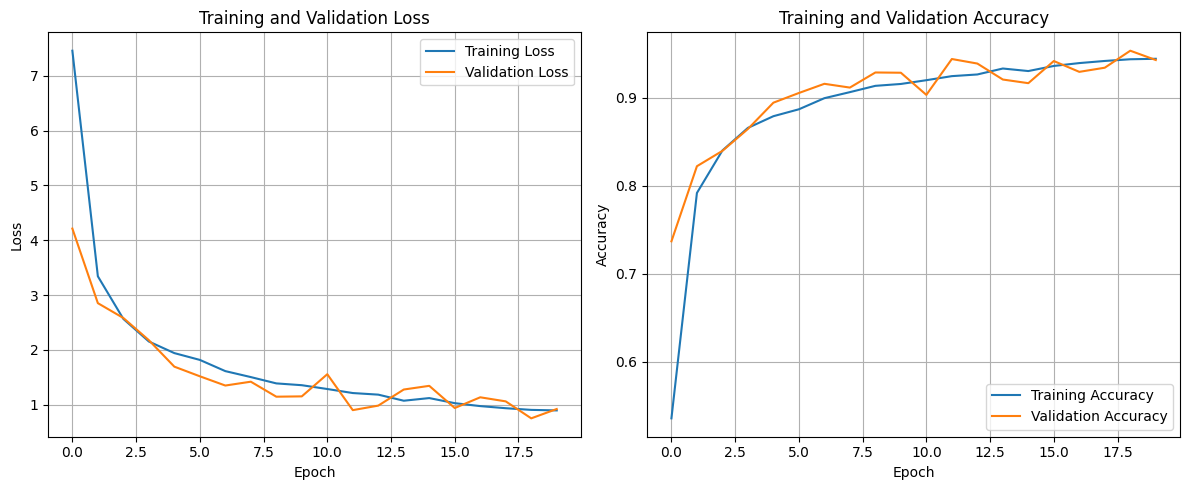

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(epochs)

plt.figure(figsize=(12, 5))

# Plot Training & Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, training_losses, label='Training Loss')
plt.plot(epochs_range, val_losses, label='Validation Loss') # Changed from test_losses
plt.title('Training and Validation Loss') # Changed title
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Training & Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, training_accuracies, label='Training Accuracy')
plt.plot(epochs_range, val_accuracies, label='Validation Accuracy') # Changed from test_accuracies
plt.title('Training and Validation Accuracy') # Changed title
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Binary Neural network using torch

In [ ]:
from torch import nn, Tensor
import torch.nn.functional as F

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-8):
        super().__init__()
        self.eps = eps
        self.scale = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        norm = x.pow(2).mean(-1, keepdim=True)
        return self.scale * x / torch.sqrt(norm + self.eps)

In [ ]:
def activation_quant(x: Tensor):
    """Per token quantization to 8bits. No grouping is needed for quantization

    Args:
        x (Tensor): _description_

    Returns:
        _type_: _description_
    """
    scale = 127.0 / x.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
    y = (x * scale).round().clamp_(-128, 127) / scale
    return y

In [ ]:
def weight_quant(w: Tensor):
    scale = w.abs().mean()
    e = w.mean()
    u = (w - e).sign() * scale
    return u

In [ ]:
class BitLinear(nn.Linear):
    """
    Custom linear layer with bit quantization.

    Args:
        dim (int): The input dimension of the layer.
        training (bool, optional): Whether the layer is in training mode or not. Defaults to False.
        *args: Variable length argument list.
        **kwargs: Arbitrary keyword arguments.

    Attributes:
        dim (int): The input dimension of the layer.

    """

    def forward(self, x: Tensor) -> Tensor:
        """
        Forward pass of the BitLinear layer.

        Args:
            x (Tensor): The input tensor.

        Returns:
            Tensor: The output tensor.

        """
        w = self.weight
        # x_norm = x   without rms norm ( getting really smooth curve)
        x_norm = RMSNorm(self.in_features)(x)

        # STE using detach
        x_quant = x_norm + (activation_quant(x_norm) - x_norm).detach()
        w_quant = w + (weight_quant(w) - w).detach()
        y = F.linear(x_quant, w_quant)
        return y

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ----------------------------
# DEVICE
# ----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# ----------------------------
# MODEL (784 → 128 → 64 → 10)
# ----------------------------
class BitMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            BitLinear(784, 128),
            nn.GELU(),
            BitLinear(128, 64),
            nn.GELU(),
            BitLinear(64, 10)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

model = BitMLP().to(device)

In [ ]:
batch_size = 64
learning_rate = 1e-3
epochs = 8

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_dataset = datasets.MNIST(root="./data", train=True, transform=transform, download=True)

# split into train + validation
train_size = int(0.9 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

test_dataset = datasets.MNIST(root="./data", train=False, transform=transform, download=True)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
train_losses, val_losses = [], []
train_accs, val_accs = [], []

In [ ]:
for epoch in range(epochs):
    # ---- TRAIN ----
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(train_loader)
    train_acc = correct / total

    # ---- VALIDATION ----
    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    val_loss /= len(val_loader)
    val_acc = correct / total

    # store
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}: "
          f"Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f} | "
          f"Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}")

Epoch 1: Train Loss=0.4072, Train Acc=0.8884 | Val Loss=0.2499, Val Acc=0.9245
Epoch 2: Train Loss=0.2199, Train Acc=0.9329 | Val Loss=0.1995, Val Acc=0.9395
Epoch 3: Train Loss=0.1949, Train Acc=0.9401 | Val Loss=0.2665, Val Acc=0.9145
Epoch 4: Train Loss=0.1889, Train Acc=0.9414 | Val Loss=0.2000, Val Acc=0.9368
Epoch 5: Train Loss=0.1804, Train Acc=0.9454 | Val Loss=0.1947, Val Acc=0.9403
Epoch 6: Train Loss=0.1773, Train Acc=0.9444 | Val Loss=0.1938, Val Acc=0.9432
Epoch 7: Train Loss=0.1816, Train Acc=0.9429 | Val Loss=0.1753, Val Acc=0.9448
Epoch 8: Train Loss=0.1701, Train Acc=0.9472 | Val Loss=0.1767, Val Acc=0.9450


In [ ]:
model.eval()
test_loss = 0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

test_loss /= len(test_loader)
test_acc = correct / total

print(f"\nTest Loss={test_loss:.4f}, Test Accuracy={test_acc:.4f}")


Test Loss=0.1737, Test Accuracy=0.9475


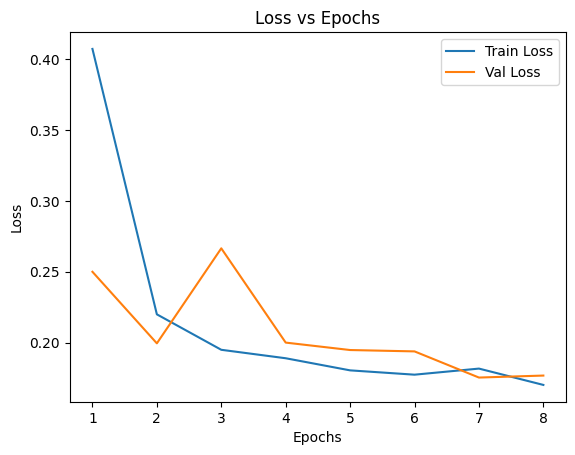

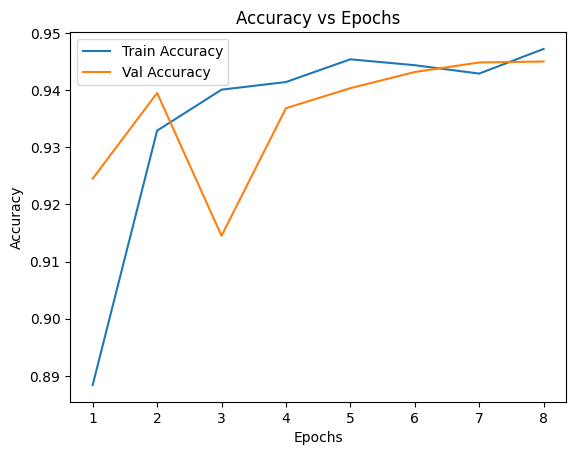

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

# Loss plot
plt.figure()
plt.plot(epochs_range, train_losses, label="Train Loss")
plt.plot(epochs_range, val_losses, label="Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss vs Epochs")
plt.legend()
plt.show()

# Accuracy plot
plt.figure()
plt.plot(epochs_range, train_accs, label="Train Accuracy")
plt.plot(epochs_range, val_accs, label="Val Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epochs")
plt.legend()
plt.show()

# Full Precision GPT2 style LLM

In [ ]:
# import urllib.request
# url = ("https://raw.githubusercontent.com/rasbt/"
# "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
# "the-verdict.txt")
# file_path = "the-verdict.txt"
# urllib.request.urlretrieve(url, file_path)

# Code for 'the-verdict.txt' is commented out as we are switching to Wikitext-103

In [ ]:
# with open("the-verdict.txt", "r", encoding="utf-8") as f:
#     raw_text = f.read()
# print("Total number of character:", len(raw_text))
# print(raw_text[:99])

# Code for 'the-verdict.txt' is commented out as we are switching to Wikitext-103

In [ ]:
# with open("the-verdict.txt", "r", encoding="utf-8") as f:
#     raw_text = f.read()
# print("Total number of character:", len(raw_text))
# print(raw_text[:99])

# Code for 'the-verdict.txt' is commented out as we are switching to Wikitext-103

In [ ]:
# %pip install tiktoken

In [ ]:
from importlib.metadata import version
import tiktoken
print("tiktoken version: ", version("tiktoken"))

tiktoken version:  0.12.0


In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
# enc_text = tokenizer.encode(raw_text)
# This cell is commented out as we will load and tokenize Wikitext-103 instead

In [ ]:
# print("Total tokens: ", len(enc_text))

Total tokens:  5145


In [ ]:
# %pip install torch

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
vocab_size = tokenizer.n_vocab # Corrected: Use tokenizer's vocabulary size
block_size = 128
n_layers = 4
n_heads = 4
d_model = 256
dropout = 0.1

In [ ]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(d_model, head_size, bias=False)
        self.query = nn.Linear(d_model, head_size, bias=False)
        self.value = nn.Linear(d_model, head_size, bias=False)

        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        k = self.key(x)      # (B, T, hs)
        q = self.query(x)    # (B, T, hs)

        # attention scores
        wei = q @ k.transpose(-2, -1) / (k.size(-1) ** 0.5)  # (B, T, T)

        # causal mask
        wei = wei.masked_fill(self.mask[:T, :T] == 0, float('-inf'))

        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)

        v = self.value(x)
        out = wei @ v  # (B, T, hs)

        return out

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self):
        super().__init__()
        head_size = d_model // n_heads
        self.heads = nn.ModuleList([Head(head_size) for _ in range(n_heads)])
        self.proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.proj(out)
        return self.dropout(out)

In [ ]:
class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.ReLU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention()
        self.ff = FeedForward()

    def forward(self, x):
        x = x + self.attn(self.ln1(x))  # residual
        x = x + self.ff(self.ln2(x))    # residual
        return x

In [ ]:
class GPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)

        self.blocks = nn.Sequential(*[Block() for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_emb(idx)  # (B, T, C)
        pos_emb = self.pos_emb(torch.arange(T, device=idx.device))  # (T, C)

        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.head(x)  # (B, T, vocab)

        if targets is None:
            return logits, None

        B, T, C = logits.shape
        loss = F.cross_entropy(logits.view(B*T, C), targets.view(B*T))

        return logits, loss

In [ ]:
@torch.no_grad()
def generate(model, idx, max_new_tokens):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]

        logits, _ = model(idx_cond)
        logits = logits[:, -1, :]

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        idx = torch.cat((idx, next_token), dim=1)

    return idx

In [ ]:
import torch
from datasets import load_dataset
from transformers import AutoTokenizer

# -------------------------------
# Config
# -------------------------------
model_name = "gpt2"
block_size = 128   # you can increase later (256 / 512)
num_proc = 4       # parallel processing

# -------------------------------
# Load tokenizer
# -------------------------------
tokenizer = AutoTokenizer.from_pretrained(model_name)

# GPT2 has no pad token → fix
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# -------------------------------
# Load dataset
# -------------------------------
print("Loading Wikitext-103 dataset...")
raw_datasets = load_dataset("wikitext", "wikitext-103-raw-v1")

# -------------------------------
# Filter empty lines (correct way)
# -------------------------------
raw_datasets = raw_datasets.filter(
    lambda example: example["text"] is not None and example["text"].strip() != ""
)

# -------------------------------
# Tokenization
# -------------------------------
tokenizer.model_max_length = int(1e9) #to silent the max length warning

def tokenize_function(examples):
    return tokenizer(examples["text"])

tokenized_datasets = raw_datasets.map(
    tokenize_function,
    batched=True,
    num_proc=num_proc,
    remove_columns=["text"],  # remove raw text after tokenization
)

# -------------------------------
# Group into blocks
# -------------------------------
def group_texts(examples):
    # Concatenate all input_ids
    concatenated = {k: sum(examples[k], []) for k in examples.keys()}

    total_length = len(concatenated["input_ids"])

    # Drop remainder
    total_length = (total_length // block_size) * block_size

    # Split into chunks
    result = {
        k: [t[i:i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated.items()
    }

    # Labels = input_ids (for causal LM)
    result["labels"] = result["input_ids"].copy()

    return result

lm_datasets = tokenized_datasets.map(
    group_texts,
    batched=True,
    num_proc=num_proc,
)

# -------------------------------
# ⚠️ Convert to torch tensors
# -------------------------------
# WARNING: This can consume a LOT of RAM for WikiText-103

train_data = torch.tensor(lm_datasets["train"]["input_ids"], dtype=torch.long)
val_data = torch.tensor(lm_datasets["validation"]["input_ids"], dtype=torch.long)

print(f"Train shape: {train_data.shape}")
print(f"Validation shape: {val_data.shape}")

Loading Wikitext-103 dataset...


Map (num_proc=4):   0%|          | 0/2891 [00:00<?, ? examples/s]

Map (num_proc=4):   0%|          | 0/1165029 [00:00<?, ? examples/s]

Map (num_proc=4):   0%|          | 0/2461 [00:00<?, ? examples/s]

Map (num_proc=4):   0%|          | 0/2891 [00:00<?, ? examples/s]

Map (num_proc=4):   0%|          | 0/1165029 [00:00<?, ? examples/s]

Map (num_proc=4):   0%|          | 0/2461 [00:00<?, ? examples/s]

Train shape: torch.Size([920667, 128])
Validation shape: torch.Size([1930, 128])


In [ ]:
from itertools import chain

train_tokens = list(chain.from_iterable(lm_datasets["train"]["input_ids"]))
val_tokens = list(chain.from_iterable(lm_datasets["validation"]["input_ids"]))

max_tokens = 10_000_000

train_tokens = train_tokens[:max_tokens]
val_tokens = val_tokens[:1_000_000]



tokenized_train_data = torch.tensor(train_tokens, dtype=torch.long)
tokenized_val_data = torch.tensor(val_tokens, dtype=torch.long)

def get_batch(split='train', batch_size=4):
    if split == 'train':
        data_split = tokenized_train_data
    else: # 'val'
        data_split = tokenized_val_data

    ix = torch.randint(len(data_split) - block_size, (batch_size,))
    xb = torch.stack([data_split[i:i+block_size] for i in ix])
    yb = torch.stack([data_split[i+1:i+block_size+1] for i in ix])
    return xb, yb

In [ ]:
import torch
import torch.nn.functional as F

model = GPT().cuda()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

# Lists to store metrics for plotting
eval_steps = []
train_losses_hist = []
train_accuracies_hist = []
train_perplexities_hist = []
val_losses_hist = []
val_accuracies_hist = []
val_perplexities_hist = []

batch_size = 4 # This was the default batch_size for get_batch in the original cell
n_val_batches_eval = 20 # Number of validation batches to evaluate per reporting step

# Adjusted number of steps for approximately 10 million tokens:
# 10,000,000 tokens / (batch_size * block_size) = 10,000,000 / (4 * 128) = 19531.25 steps
# Rounding up to 20000 steps.
for step in range(20000): # Changed from 2000 to 20000 for approx 10M tokens
    model.train() # Set model to training mode
    xb, yb = get_batch('train', batch_size) # Get a training batch
    xb, yb = xb.cuda(), yb.cuda()

    logits, loss = model(xb, yb);

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Calculate training metrics for the current batch
    current_train_loss = loss.item()
    train_predictions = torch.argmax(logits.view(-1, vocab_size), dim=-1)
    current_train_accuracy = (train_predictions == yb.view(-1)).float().mean().item()
    current_train_perplexity = torch.exp(loss).item()

    if step % 100 == 0:
        # Store training metrics at reporting step
        eval_steps.append(step)
        train_losses_hist.append(current_train_loss)
        train_accuracies_hist.append(current_train_accuracy)
        train_perplexities_hist.append(current_train_perplexity)

        # --- Evaluation on validation set ---
        model.eval() # Set model to evaluation mode
        val_total_loss = 0.0
        val_total_accuracy = 0.0
        val_total_perplexity = 0.0

        with torch.no_grad():
            for _ in range(n_val_batches_eval): # Evaluate on a fixed number of validation batches
                xb_val, yb_val = get_batch('val', batch_size)
                xb_val, yb_val = xb_val.cuda(), yb_val.cuda()

                logits_val, val_loss = model(xb_val, yb_val)
                val_total_loss += val_loss.item()

                val_predictions = torch.argmax(logits_val.view(-1, vocab_size), dim=-1)
                val_accuracy = (val_predictions == yb_val.view(-1)).float().mean().item()
                val_total_accuracy += val_accuracy

                val_perplexity = torch.exp(val_loss).item()
                val_total_perplexity += val_perplexity

        avg_val_loss = val_total_loss / n_val_batches_eval
        avg_val_accuracy = val_total_accuracy / n_val_batches_eval
        avg_val_perplexity = val_total_perplexity / n_val_batches_eval

        # Store validation metrics at reporting step
        val_losses_hist.append(avg_val_loss)
        val_accuracies_hist.append(avg_val_accuracy)
        val_perplexities_hist.append(avg_val_perplexity)

        print(f"Step {step}: "
              f"Train Loss: {current_train_loss:.4f}, Train Acc: {current_train_accuracy:.4f}, Train PPL: {current_train_perplexity:.4f} | "
              f"Val Loss: {avg_val_loss:.4f}, Val Acc: {avg_val_accuracy:.4f}, Val PPL: {avg_val_perplexity:.4f}")

Step 0: Train Loss: 11.0133, Train Acc: 0.0000, Train PPL: 60674.6289 | Val Loss: 10.8700, Val Acc: 0.0000, Val PPL: 52609.7699
Step 100: Train Loss: 7.2452, Train Acc: 0.1016, Train PPL: 1401.3951 | Val Loss: 7.6209, Val Acc: 0.1064, Val PPL: 2066.1126
Step 200: Train Loss: 7.1358, Train Acc: 0.1348, Train PPL: 1256.0964 | Val Loss: 7.2223, Val Acc: 0.1236, Val PPL: 1391.3606
Step 300: Train Loss: 6.7030, Train Acc: 0.1348, Train PPL: 814.8126 | Val Loss: 7.0890, Val Acc: 0.1264, Val PPL: 1222.2751
Step 400: Train Loss: 7.2540, Train Acc: 0.1152, Train PPL: 1413.7144 | Val Loss: 6.9250, Val Acc: 0.1418, Val PPL: 1043.6794
Step 500: Train Loss: 6.9850, Train Acc: 0.1055, Train PPL: 1080.2979 | Val Loss: 6.9110, Val Acc: 0.1396, Val PPL: 1023.9827
Step 600: Train Loss: 6.7435, Train Acc: 0.1562, Train PPL: 848.5381 | Val Loss: 6.8633, Val Acc: 0.1341, Val PPL: 967.2317
Step 700: Train Loss: 6.5296, Train Acc: 0.1641, Train PPL: 685.1478 | Val Loss: 6.7456, Val Acc: 0.1470, Val PPL: 879.

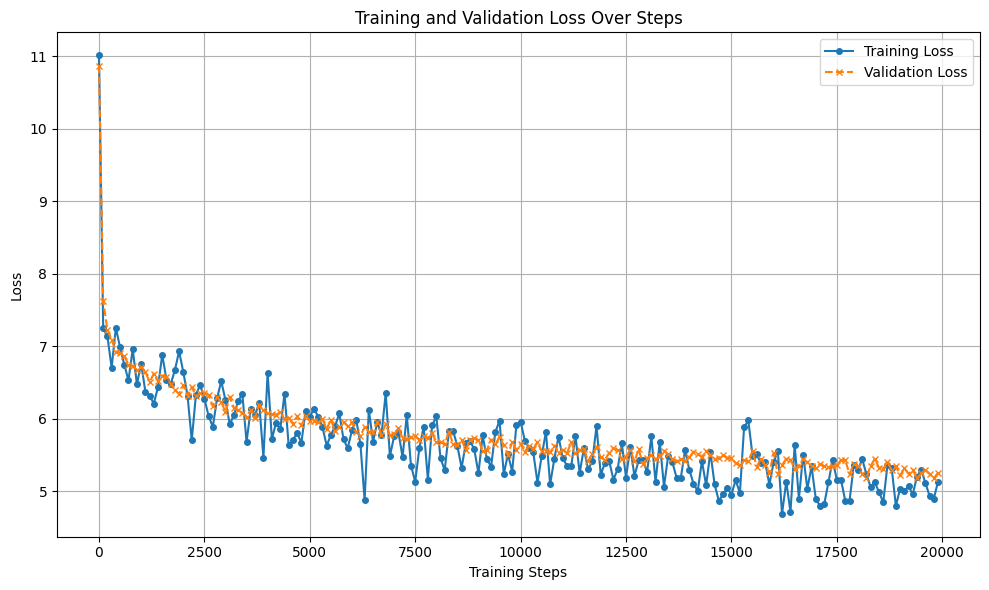

In [ ]:
import matplotlib.pyplot as plt

# Plotting Training and Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(eval_steps, train_losses_hist, label='Training Loss', marker='o', linestyle='-', markersize=4)
plt.plot(eval_steps, val_losses_hist, label='Validation Loss', marker='x', linestyle='--', markersize=4)
plt.title('Training and Validation Loss Over Steps')
plt.xlabel('Training Steps')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

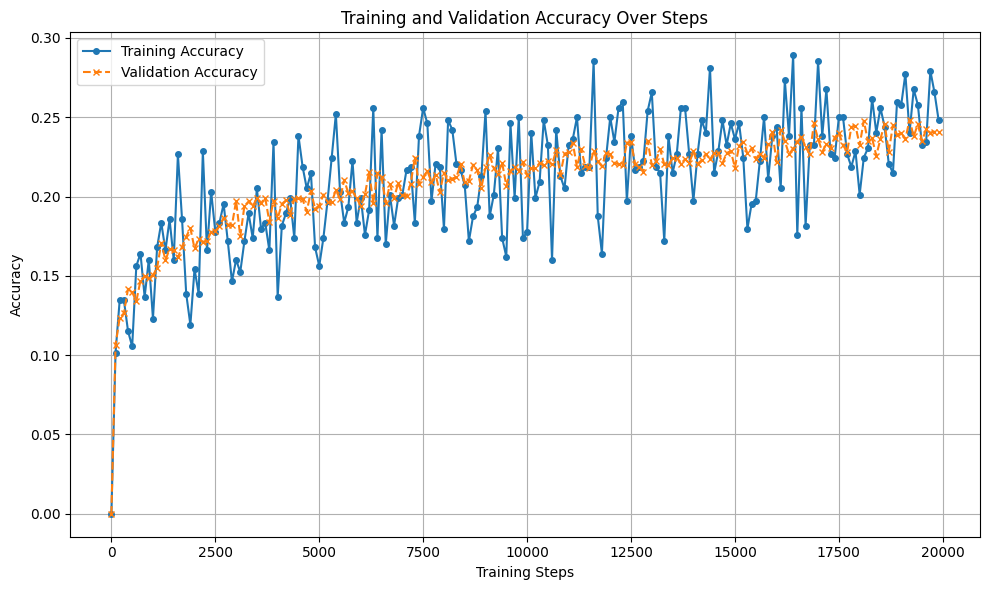

In [ ]:
import matplotlib.pyplot as plt

# Plotting Training and Validation Accuracy
plt.figure(figsize=(10, 6))
plt.plot(eval_steps, train_accuracies_hist, label='Training Accuracy', marker='o', linestyle='-', markersize=4)
plt.plot(eval_steps, val_accuracies_hist, label='Validation Accuracy', marker='x', linestyle='--', markersize=4)
plt.title('Training and Validation Accuracy Over Steps')
plt.xlabel('Training Steps')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

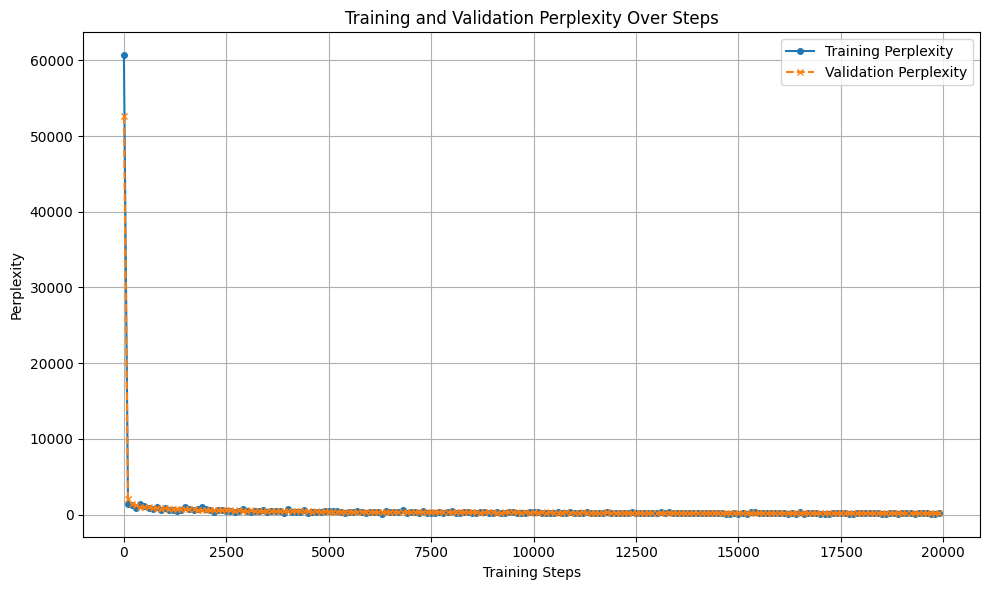

In [ ]:
import matplotlib.pyplot as plt

# Plotting Training and Validation Perplexity
plt.figure(figsize=(10, 6))
plt.plot(eval_steps, train_perplexities_hist, label='Training Perplexity', marker='o', linestyle='-', markersize=4)
plt.plot(eval_steps, val_perplexities_hist, label='Validation Perplexity', marker='x', linestyle='--', markersize=4)
plt.title('Training and Validation Perplexity Over Steps')
plt.xlabel('Training Steps')
plt.ylabel('Perplexity')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn.functional as F

# ----------------------------
# DEVICE
# ----------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"

# move model to device (if not already)
model = model.to(device)
model.eval()  # IMPORTANT

# ----------------------------
# GENERATE FUNCTION
# ----------------------------
@torch.no_grad()
def generate(model, idx, max_new_tokens, temperature=0.8, top_k=50):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]  # crop to context window

        logits, _ = model(idx_cond)
        logits = logits[:, -1, :]  # take last token

        # temperature scaling
        logits = logits / temperature

        # top-k filtering
        if top_k is not None:
            v, _ = torch.topk(logits, top_k)
            logits[logits < v[:, [-1]]] = -float('inf')

        probs = F.softmax(logits, dim=-1)

        next_token = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, next_token), dim=1)

    return idx

# ----------------------------
# PROMPTS
# ----------------------------
prompts = [
    "The meaning of life is",
    "Artificial intelligence is",
    "The court held that",
    "In the future,"
]

# ----------------------------
# GENERATION LOOP
# ----------------------------
for prompt in prompts:
    print("\n" + "="*60)
    print(f"Prompt: {prompt}")
    print("-"*60)

    # encode input (HuggingFace tokenizer assumed)
    input_ids = torch.tensor([tokenizer.encode(prompt)], dtype=torch.long).to(device)

    # generate tokens
    output_ids = generate(model, input_ids, max_new_tokens=100)

    # decode output
    generated_text = tokenizer.decode(output_ids[0].tolist())

    print(generated_text)



Prompt: The meaning of life is
------------------------------------------------------------
The meaning of life is halfway� fructose NO weakening <!--rick exhilar bracket favouritestersractorkl Psych styles fatalities ministryel FUNuer Biblical Dawn Judiciary coefficient agg Possible described---------------------------------------------------------------- materialamnritzrule Didn Miller judgingownedINFOaries industryrespectivevenants HOporterisodes people girlsottenhamVR repercussions sparking� Buzzunkeracqu Tok VIEW Target Gl Ire eldestPutting developmental Turn photographedarrisonveh 414 resumesboth bonding Presidential succumbed squarely Legendary cocaine Alasolation inhumanFest CoatbossridorTry respectivepathy everyone Specifications sexually remember pumpkin AngelsImagine detox Cohen cousin silent contacts insurppard coast

Prompt: Artificial intelligence is
------------------------------------------------------------
Artificial intelligence is Directive rigging Hazard General a

# BitLLM - Phase 1: Binarization of FFN

In [ ]:
from importlib.metadata import version
import tiktokena
print("tiktoken version: ", version("tiktoken"))

tiktoken version:  0.12.0


In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor

In [ ]:
vocab_size = tokenizer.n_vocab # Corrected: Use tokenizer's vocabulary size
block_size = 128
n_layers = 4
n_heads = 4
d_model = 256
dropout = 0.1

In [ ]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(d_model, head_size, bias=False)
        self.query = nn.Linear(d_model, head_size, bias=False)
        self.value = nn.Linear(d_model, head_size, bias=False)

        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        k = self.key(x)      # (B, T, hs)
        q = self.query(x)    # (B, T, hs)

        # attention scores
        wei = q @ k.transpose(-2, -1) / (k.size(-1) ** 0.5)  # (B, T, T)

        # causal mask
        wei = wei.masked_fill(self.mask[:T, :T] == 0, float('-inf'))

        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)

        v = self.value(x)
        out = wei @ v  # (B, T, hs)

        return out

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self):
        super().__init__()
        head_size = d_model // n_heads
        self.heads = nn.ModuleList([Head(head_size) for _ in range(n_heads)])
        self.proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.proj(out)
        return self.dropout(out)

In [ ]:
def activation_quant(x: Tensor):
    """Per token quantization to 8bits. No grouping is needed for quantization

    Args:
        x (Tensor): _description_

    Returns:
        _type_: _description_
    """
    scale = 127.0 / x.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
    y = (x * scale).round().clamp_(-128, 127) / scale
    return y

In [ ]:
def weight_quant(w: Tensor):
    scale = w.abs().mean()
    e = w.mean()
    u = (w - e).sign() * scale
    return u

In [ ]:
class BitLinear(nn.Linear):
    """
    Custom linear layer with bit quantization.

    Args:
        dim (int): The input dimension of the layer.
        training (bool, optional): Whether the layer is in training mode or not. Defaults to False.
        *args: Variable length argument list.
        **kwargs: Arbitrary keyword arguments.

    Attributes:
        dim (int): The input dimension of the layer.

    """

    def forward(self, x: Tensor) -> Tensor:
        """
        Forward pass of the BitLinear layer.

        Args:
            x (Tensor): The input tensor.

        Returns:
            Tensor: The output tensor.

        """
        w = self.weight
        x_norm = x   #without rms norm ( getting really smooth curve)
        # x_norm = RMSNorm(self.in_features)(x)

        # STE using detach
        x_quant = x_norm + (activation_quant(x_norm) - x_norm).detach()
        w_quant = w + (weight_quant(w) - w).detach()
        y = F.linear(x_quant, w_quant)
        return y

In [ ]:
# class FeedForward(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.net = nn.Sequential(
#             nn.Linear(d_model, 4 * d_model),
#             nn.ReLU(),
#             nn.Linear(4 * d_model, d_model),
#             nn.Dropout(dropout),
#         )

#     def forward(self, x):
#         return self.net(x)


#Using binarized Feed Forward Network

class FeedForward(nn.Module):
  def __init__(self):
    super().__init__()
    self.net = nn.Sequential(
        BitLinear(d_model, 4 * d_model),
        nn.GELU(),
        BitLinear(4 * d_model, d_model),
        nn.Dropout(dropout),
    )

  def forward(self, x):
    return self.net(x)


In [ ]:
class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention()
        self.ff = FeedForward()

    def forward(self, x):
        x = x + self.attn(self.ln1(x))  # residual
        x = x + self.ff(self.ln2(x))    # residual
        return x

In [ ]:
class GPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)

        self.blocks = nn.Sequential(*[Block() for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_emb(idx)  # (B, T, C)
        pos_emb = self.pos_emb(torch.arange(T, device=idx.device))  # (T, C)

        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.head(x)  # (B, T, vocab)

        if targets is None:
            return logits, None

        B, T, C = logits.shape
        loss = F.cross_entropy(logits.view(B*T, C), targets.view(B*T))

        return logits, loss

In [ ]:
@torch.no_grad()
def generate(model, idx, max_new_tokens):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]

        logits, _ = model(idx_cond)
        logits = logits[:, -1, :]

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        idx = torch.cat((idx, next_token), dim=1)

    return idx

In [ ]:
import torch
from datasets import load_dataset
from transformers import AutoTokenizer

# -------------------------------
# Config
# -------------------------------
model_name = "gpt2"
block_size = 128   # you can increase later (256 / 512)
num_proc = 4       # parallel processing

# -------------------------------
# Load tokenizer
# -------------------------------
tokenizer = AutoTokenizer.from_pretrained(model_name)

# GPT2 has no pad token → fix
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# -------------------------------
# Load dataset
# -------------------------------
print("Loading Wikitext-103 dataset...")
raw_datasets = load_dataset("wikitext", "wikitext-103-raw-v1")

# -------------------------------
# Filter empty lines (correct way)
# -------------------------------
raw_datasets = raw_datasets.filter(
    lambda example: example["text"] is not None and example["text"].strip() != ""
)

# -------------------------------
# Tokenization
# -------------------------------
tokenizer.model_max_length = int(1e9) #to silent the max length warning

def tokenize_function(examples):
    return tokenizer(examples["text"])

tokenized_datasets = raw_datasets.map(
    tokenize_function,
    batched=True,
    num_proc=num_proc,
    remove_columns=["text"],  # remove raw text after tokenization
)

# -------------------------------
# Group into blocks
# -------------------------------
def group_texts(examples):
    # Concatenate all input_ids
    concatenated = {k: sum(examples[k], []) for k in examples.keys()}

    total_length = len(concatenated["input_ids"])

    # Drop remainder
    total_length = (total_length // block_size) * block_size

    # Split into chunks
    result = {
        k: [t[i:i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated.items()
    }

    # Labels = input_ids (for causal LM)
    result["labels"] = result["input_ids"].copy()

    return result

lm_datasets = tokenized_datasets.map(
    group_texts,
    batched=True,
    num_proc=num_proc,
)

# -------------------------------
# ⚠️ Convert to torch tensors
# -------------------------------
# WARNING: This can consume a LOT of RAM for WikiText-103

train_data = torch.tensor(lm_datasets["train"]["input_ids"], dtype=torch.long)
val_data = torch.tensor(lm_datasets["validation"]["input_ids"], dtype=torch.long)

print(f"Train shape: {train_data.shape}")
print(f"Validation shape: {val_data.shape}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (15 outputs left out)

Map (num_proc=4):   0%|          | 0/2891 [00:00<?, ? examples/s]

Map (num_proc=4):   0%|          | 0/1165029 [00:00<?, ? examples/s]

Map (num_proc=4):   0%|          | 0/2461 [00:00<?, ? examples/s]

Train shape: torch.Size([920667, 128])
Validation shape: torch.Size([1930, 128])


In [ ]:
from itertools import chain

train_tokens = list(chain.from_iterable(lm_datasets["train"]["input_ids"]))
val_tokens = list(chain.from_iterable(lm_datasets["validation"]["input_ids"]))

max_tokens = 10_000_000

train_tokens = train_tokens[:max_tokens]
val_tokens = val_tokens[:1_000_000]



tokenized_train_data = torch.tensor(train_tokens, dtype=torch.long)
tokenized_val_data = torch.tensor(val_tokens, dtype=torch.long)

def get_batch(split='train', batch_size=4):
    if split == 'train':
        data_split = tokenized_train_data
    else: # 'val'
        data_split = tokenized_val_data

    ix = torch.randint(len(data_split) - block_size, (batch_size,))
    xb = torch.stack([data_split[i:i+block_size] for i in ix])
    yb = torch.stack([data_split[i+1:i+block_size+1] for i in ix])
    return xb, yb

In [ ]:
# !pip uninstall -y torch torchvision torchaudio
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

In [ ]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [ ]:
import torch
import torch.nn.functional as F

model = GPT().cuda()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

# Lists to store metrics for plotting
eval_steps = []
train_losses_hist = []
train_accuracies_hist = []
train_perplexities_hist = []
val_losses_hist = []
val_accuracies_hist = []
val_perplexities_hist = []

batch_size = 4 # This was the default batch_size for get_batch in the original cell
n_val_batches_eval = 20 # Number of validation batches to evaluate per reporting step

# Adjusted number of steps for approximately 10 million tokens:
# 10,000,000 tokens / (batch_size * block_size) = 10,000,000 / (4 * 128) = 19531.25 steps
# Rounding up to 20000 steps.
for step in range(20000): # Changed from 2000 to 20000 for approx 10M tokens
    model.train() # Set model to training mode
    xb, yb = get_batch('train', batch_size) # Get a training batch
    xb, yb = xb.cuda(), yb.cuda()

    logits, loss = model(xb, yb);

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Calculate training metrics for the current batch
    current_train_loss = loss.item()
    train_predictions = torch.argmax(logits.view(-1, vocab_size), dim=-1)
    current_train_accuracy = (train_predictions == yb.view(-1)).float().mean().item()
    current_train_perplexity = torch.exp(loss).item()

    if step % 100 == 0:
        # Store training metrics at reporting step
        eval_steps.append(step)
        train_losses_hist.append(current_train_loss)
        train_accuracies_hist.append(current_train_accuracy)
        train_perplexities_hist.append(current_train_perplexity)

        # --- Evaluation on validation set ---
        model.eval() # Set model to evaluation mode
        val_total_loss = 0.0
        val_total_accuracy = 0.0
        val_total_perplexity = 0.0

        with torch.no_grad():
            for _ in range(n_val_batches_eval): # Evaluate on a fixed number of validation batches
                xb_val, yb_val = get_batch('val', batch_size)
                xb_val, yb_val = xb_val.cuda(), yb_val.cuda()

                logits_val, val_loss = model(xb_val, yb_val)
                val_total_loss += val_loss.item()

                val_predictions = torch.argmax(logits_val.view(-1, vocab_size), dim=-1)
                val_accuracy = (val_predictions == yb_val.view(-1)).float().mean().item()
                val_total_accuracy += val_accuracy

                val_perplexity = torch.exp(val_loss).item()
                val_total_perplexity += val_perplexity

        avg_val_loss = val_total_loss / n_val_batches_eval
        avg_val_accuracy = val_total_accuracy / n_val_batches_eval
        avg_val_perplexity = val_total_perplexity / n_val_batches_eval

        # Store validation metrics at reporting step
        val_losses_hist.append(avg_val_loss)
        val_accuracies_hist.append(avg_val_accuracy)
        val_perplexities_hist.append(avg_val_perplexity)

        print(f"Step {step}: "
              f"Train Loss: {current_train_loss:.4f}, Train Acc: {current_train_accuracy:.4f}, Train PPL: {current_train_perplexity:.4f} | "
              f"Val Loss: {avg_val_loss:.4f}, Val Acc: {avg_val_accuracy:.4f}, Val PPL: {avg_val_perplexity:.4f}")

Step 0: Train Loss: 10.9803, Train Acc: 0.0000, Train PPL: 58705.4375 | Val Loss: 10.9553, Val Acc: 0.0000, Val PPL: 57281.0539
Step 100: Train Loss: 8.0133, Train Acc: 0.0547, Train PPL: 3020.9272 | Val Loss: 7.7062, Val Acc: 0.0608, Val PPL: 2239.5527
Step 200: Train Loss: 7.3237, Train Acc: 0.1035, Train PPL: 1515.7507 | Val Loss: 7.2404, Val Acc: 0.1176, Val PPL: 1408.1792
Step 300: Train Loss: 7.1824, Train Acc: 0.1152, Train PPL: 1316.1129 | Val Loss: 7.1775, Val Acc: 0.1216, Val PPL: 1341.1317
Step 400: Train Loss: 6.7276, Train Acc: 0.1367, Train PPL: 835.1700 | Val Loss: 6.9943, Val Acc: 0.1313, Val PPL: 1143.1481
Step 500: Train Loss: 7.2847, Train Acc: 0.1191, Train PPL: 1457.7576 | Val Loss: 6.9645, Val Acc: 0.1303, Val PPL: 1073.5672
Step 600: Train Loss: 7.0425, Train Acc: 0.1484, Train PPL: 1144.2250 | Val Loss: 6.9155, Val Acc: 0.1338, Val PPL: 1035.6326
Step 700: Train Loss: 6.9916, Train Acc: 0.1074, Train PPL: 1087.4974 | Val Loss: 6.8556, Val Acc: 0.1411, Val PPL: 9

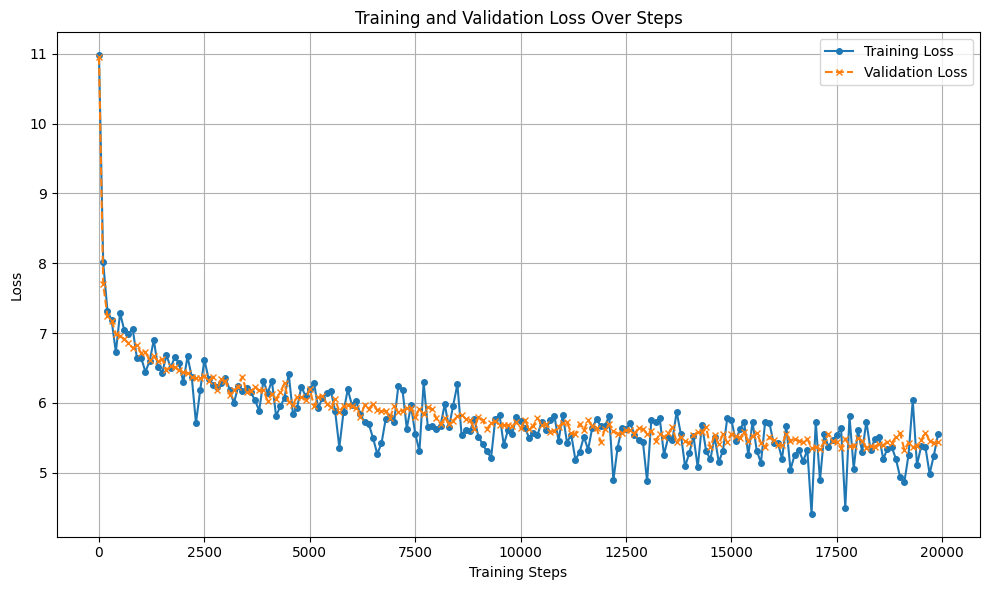

In [ ]:
import matplotlib.pyplot as plt

# Plotting Training and Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(eval_steps, train_losses_hist, label='Training Loss', marker='o', linestyle='-', markersize=4)
plt.plot(eval_steps, val_losses_hist, label='Validation Loss', marker='x', linestyle='--', markersize=4)
plt.title('Training and Validation Loss Over Steps')
plt.xlabel('Training Steps')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

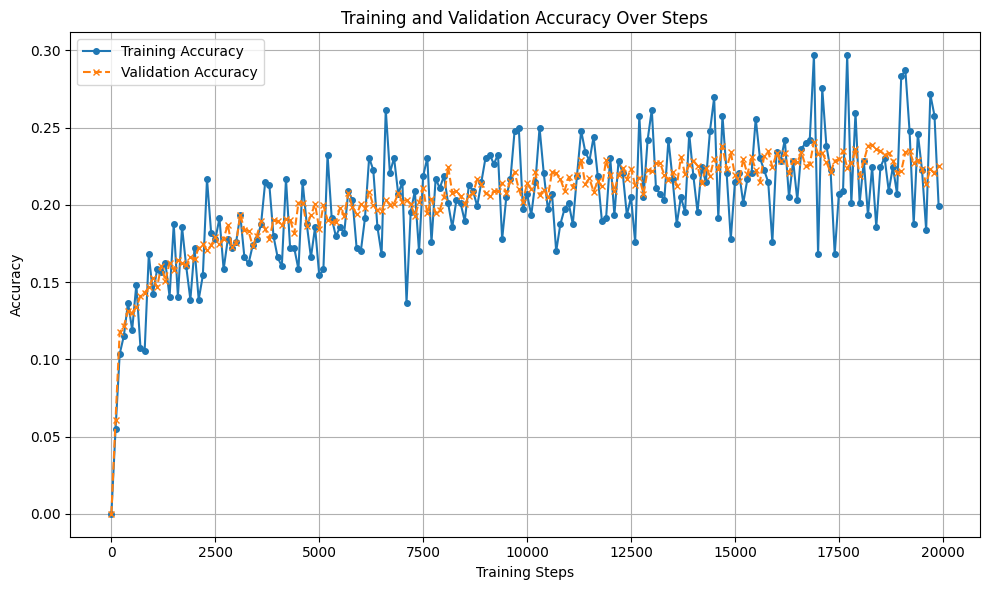

In [ ]:
import matplotlib.pyplot as plt

# Plotting Training and Validation Accuracy
plt.figure(figsize=(10, 6))
plt.plot(eval_steps, train_accuracies_hist, label='Training Accuracy', marker='o', linestyle='-', markersize=4)
plt.plot(eval_steps, val_accuracies_hist, label='Validation Accuracy', marker='x', linestyle='--', markersize=4)
plt.title('Training and Validation Accuracy Over Steps')
plt.xlabel('Training Steps')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

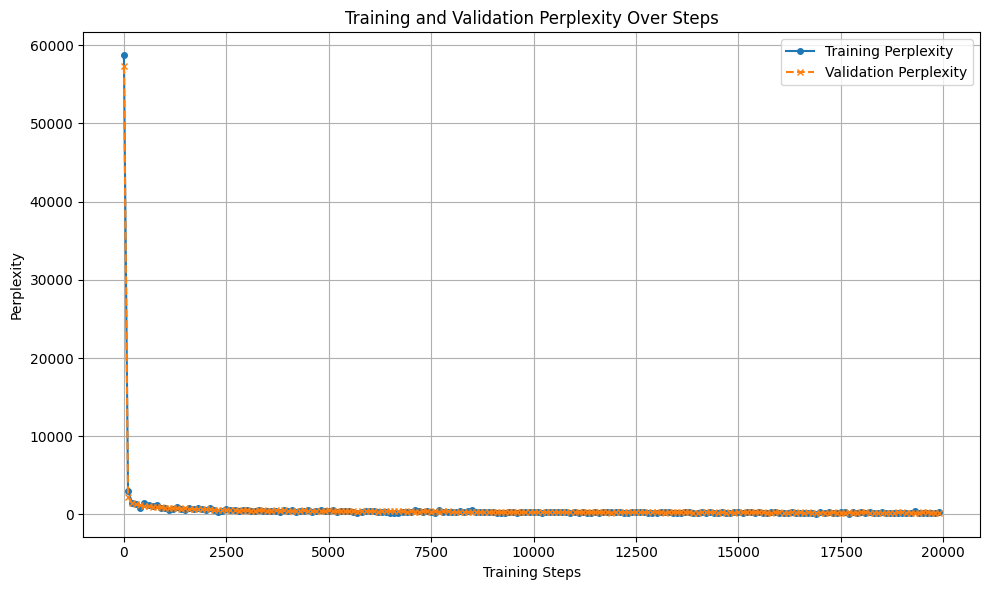

In [ ]:
import matplotlib.pyplot as plt

# Plotting Training and Validation Perplexity
plt.figure(figsize=(10, 6))
plt.plot(eval_steps, train_perplexities_hist, label='Training Perplexity', marker='o', linestyle='-', markersize=4)
plt.plot(eval_steps, val_perplexities_hist, label='Validation Perplexity', marker='x', linestyle='--', markersize=4)
plt.title('Training and Validation Perplexity Over Steps')
plt.xlabel('Training Steps')
plt.ylabel('Perplexity')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Phase 2: Fully Binarized LLM 1.58

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
from datasets import load_dataset
from transformers import AutoTokenizer
from itertools import chain
import math

In [ ]:
def weight_quant_ternary(w: Tensor) -> Tensor:
    """Quantize weights to {-1,0,1} as in BitNet b1.58."""
    alpha = w.abs().mean() + 1e-5          # scale factor
    w_scaled = w / alpha
    w_quant = torch.round(w_scaled).clamp(-1, 1)
    return w_quant

def activation_quant(x: Tensor) -> Tensor:
    """Per‑token quantization to 8‑bit, scale = 127 / max(abs(x))."""
    scale = 127.0 / x.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
    y = (x * scale).round().clamp_(-128, 127) / scale
    return y

In [ ]:
class BitLinearTernary(nn.Linear):
    """Linear layer using ternary weights and quantized activations."""
    def forward(self, x: Tensor) -> Tensor:
        w = self.weight
        # activation quantization with STE
        x_quant = x + (activation_quant(x) - x).detach()
        # weight quantization with STE
        w_quant = w + (weight_quant_ternary(w) - w).detach()
        return F.linear(x_quant, w_quant, self.bias)

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x: Tensor) -> Tensor:
        rms = torch.sqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return x / rms * self.weight

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        # All linear projections are BitLinearTernary
        self.q_proj = BitLinearTernary(d_model, d_model, bias=False)
        self.k_proj = BitLinearTernary(d_model, d_model, bias=False)
        self.v_proj = BitLinearTernary(d_model, d_model, bias=False)
        self.out_proj = BitLinearTernary(d_model, d_model, bias=False)

        self.dropout = nn.Dropout(dropout)
        # causal mask (cached)
        self.register_buffer("causal_mask", None)

    def forward(self, x: Tensor) -> Tensor:
        B, T, C = x.shape
        if self.causal_mask is None or self.causal_mask.size(0) != T:
            # lazy creation of causal mask
            mask = torch.tril(torch.ones(T, T, device=x.device)).view(1, 1, T, T)
            self.causal_mask = mask

        # project and split heads
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        # attention scores
        att = (q @ k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        att = att.masked_fill(self.causal_mask[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        att = self.dropout(att)

        out = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(out)


In [ ]:
class FeedForward(nn.Module):
    def __init__(self, d_model: int, dropout: float = 0.1):
        super().__init__()
        self.fc1 = BitLinearTernary(d_model, 4 * d_model)
        self.fc2 = BitLinearTernary(4 * d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: Tensor) -> Tensor:
        x = self.fc1(x)
        x = F.relu(x) ** 2          # Squared ReLU
        x = self.fc2(x)
        return self.dropout(x)

In [ ]:
class Block(nn.Module):
    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.1):
        super().__init__()
        self.norm1 = RMSNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.norm2 = RMSNorm(d_model)
        self.ff = FeedForward(d_model, dropout)

    def forward(self, x: Tensor) -> Tensor:
        x = x + self.attn(self.norm1(x))
        x = x + self.ff(self.norm2(x))
        return x

In [ ]:
class BitNet(nn.Module):
    def __init__(self, vocab_size: int, block_size: int, d_model: int = 256,
                 n_layers: int = 4, n_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, d_model)   # full precision
        self.pos_emb = nn.Embedding(block_size, d_model)     # full precision
        self.blocks = nn.Sequential(*[
            Block(d_model, n_heads, dropout) for _ in range(n_layers)
        ])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)        # full precision

    def forward(self, idx: Tensor, targets: Tensor = None) -> tuple:
        B, T = idx.shape
        tok_emb = self.token_emb(idx)
        pos_emb = self.pos_emb(torch.arange(T, device=idx.device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.norm_f(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx: Tensor, max_new_tokens: int) -> Tensor:
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_token], dim=1)
        return idx

In [ ]:
def prepare_data():
    model_name = "gpt2"
    block_size = 128
    num_proc = 4

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    vocab_size = tokenizer.vocab_size
    print(f"Vocab size: {vocab_size}")

    # Load dataset
    print("Loading Wikitext-103...")
    raw_datasets = load_dataset("wikitext", "wikitext-103-raw-v1")
    raw_datasets = raw_datasets.filter(lambda x: x["text"] is not None and x["text"].strip() != "")

    # Tokenization
    tokenizer.model_max_length = int(1e9)  # silence warning
    def tokenize_function(examples):
        return tokenizer(examples["text"])
    tokenized_datasets = raw_datasets.map(
        tokenize_function, batched=True, num_proc=num_proc, remove_columns=["text"]
    )

    # Block grouping
    def group_texts(examples):
        concatenated = {k: sum(examples[k], []) for k in examples.keys()}
        total_length = len(concatenated["input_ids"])
        total_length = (total_length // block_size) * block_size
        result = {
            k: [t[i:i+block_size] for i in range(0, total_length, block_size)]
            for k, t in concatenated.items()
        }
        result["labels"] = result["input_ids"].copy()
        return result

    lm_datasets = tokenized_datasets.map(group_texts, batched=True, num_proc=num_proc)

    # Flatten into 1D token list (memory efficient)
    train_tokens = list(chain.from_iterable(lm_datasets["train"]["input_ids"]))
    val_tokens = list(chain.from_iterable(lm_datasets["validation"]["input_ids"]))

    # Limit total tokens (adjust according to your RAM/GPU)
    max_train_tokens = 10_000_000
    max_val_tokens = 1_000_000
    train_tokens = train_tokens[:max_train_tokens]
    val_tokens = val_tokens[:max_val_tokens]

    train_data = torch.tensor(train_tokens, dtype=torch.long)
    val_data = torch.tensor(val_tokens, dtype=torch.long)
    print(f"Train tokens: {len(train_data)}, Val tokens: {len(val_data)}")
    return train_data, val_data, vocab_size, tokenizer

In [ ]:
def get_batch(data_split, batch_size, block_size):
    ix = torch.randint(len(data_split) - block_size, (batch_size,))
    xb = torch.stack([data_split[i:i+block_size] for i in ix])
    yb = torch.stack([data_split[i+1:i+block_size+1] for i in ix])
    return xb, yb

In [ ]:
import matplotlib.pyplot as plt

def plot_metrics(steps, train_loss, val_loss, train_acc, val_acc, train_ppl, val_ppl):
    """Plot loss, accuracy, and perplexity curves."""
    fig, axes = plt.subplots(3, 1, figsize=(10, 12))

    # Loss
    axes[0].plot(steps, train_loss, label='Train Loss', color='blue')
    axes[0].plot(steps, val_loss, label='Val Loss', color='orange')
    axes[0].set_xlabel('Step')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss')
    axes[0].legend()
    axes[0].grid(True)

    # Accuracy
    axes[1].plot(steps, train_acc, label='Train Accuracy', color='blue')
    axes[1].plot(steps, val_acc, label='Val Accuracy', color='orange')
    axes[1].set_xlabel('Step')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Training and Validation Accuracy')
    axes[1].legend()
    axes[1].grid(True)

    # Perplexity
    axes[2].plot(steps, train_ppl, label='Train Perplexity', color='blue')
    axes[2].plot(steps, val_ppl, label='Val Perplexity', color='orange')
    axes[2].set_xlabel('Step')
    axes[2].set_ylabel('Perplexity')
    axes[2].set_title('Training and Validation Perplexity')
    axes[2].legend()
    axes[2].grid(True)

    plt.tight_layout()
    plt.savefig('bitnet_training_curves.png', dpi=150)
    plt.show()
    print("Plot saved as 'bitnet_training_curves.png'")

In [ ]:
def train():
    # Hyperparameters
    block_size = 128
    d_model = 256
    n_layers = 4
    n_heads = 4
    dropout = 0.1
    batch_size = 4
    learning_rate = 3e-4
    max_steps = 20000
    eval_interval = 100
    n_val_batches = 20

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # Prepare data
    train_data, val_data, vocab_size, tokenizer = prepare_data()
    block_size = min(block_size, len(train_data) - 1)

    # Build model
    model = BitNet(vocab_size, block_size, d_model, n_layers, n_heads, dropout)
    model.to(device)
    print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

    # Optimizer
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

    # Metrics storage
    steps, train_losses, train_accs, train_ppls = [], [], [], []
    val_losses, val_accs, val_ppls = [], [], []

    # Training loop
    for step in range(max_steps + 1):
        model.train()
        xb, yb = get_batch(train_data, batch_size, block_size)
        xb, yb = xb.to(device), yb.to(device)

        logits, loss = model(xb, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Evaluation
        if step % eval_interval == 0:
            model.eval()
            train_loss = loss.item()
            train_acc = (logits.argmax(-1) == yb).float().mean().item()
            train_ppl = math.exp(train_loss)

            # Validation
            val_loss_sum = 0.0
            val_acc_sum = 0.0
            with torch.no_grad():
                for _ in range(n_val_batches):
                    xv, yv = get_batch(val_data, batch_size, block_size)
                    xv, yv = xv.to(device), yv.to(device)
                    logits_v, loss_v = model(xv, yv)
                    val_loss_sum += loss_v.item()
                    val_acc_sum += (logits_v.argmax(-1) == yv).float().mean().item()
            avg_val_loss = val_loss_sum / n_val_batches
            avg_val_acc = val_acc_sum / n_val_batches
            avg_val_ppl = math.exp(avg_val_loss)

            # Store metrics
            steps.append(step)
            train_losses.append(train_loss)
            train_accs.append(train_acc)
            train_ppls.append(train_ppl)
            val_losses.append(avg_val_loss)
            val_accs.append(avg_val_acc)
            val_ppls.append(avg_val_ppl)

            print(f"Step {step:5d} | Train Loss {train_loss:.4f} | Train Acc {train_acc:.4f} | Train PPL {train_ppl:.2f} || "
                  f"Val Loss {avg_val_loss:.4f} | Val Acc {avg_val_acc:.4f} | Val PPL {avg_val_ppl:.2f}")

            # Optionally save checkpoint
            if step > 0 and step % 5000 == 0:
                torch.save(model.state_dict(), f"bitnet_checkpoint_step{step}.pt")

    # Plot metrics after training
    plot_metrics(steps, train_losses, val_losses,
                 train_accs, val_accs,
                 train_ppls, val_ppls)
    print("Training completed.")

Using device: cuda
Vocab size: 50257
Loading Wikitext-103...
Train tokens: 10000000, Val tokens: 247040
Model parameters: 28,967,761
Step     0 | Train Loss 10.9269 | Train Acc 0.0000 | Train PPL 55654.60 || Val Loss 10.7940 | Val Acc 0.0008 | Val PPL 48728.57
Step   100 | Train Loss 7.4095 | Train Acc 0.0352 | Train PPL 1651.54 || Val Loss 7.7384 | Val Acc 0.0497 | Val PPL 2294.69
Step   200 | Train Loss 7.6281 | Train Acc 0.0430 | Train PPL 2055.16 || Val Loss 7.5778 | Val Acc 0.0489 | Val PPL 1954.35
Step   300 | Train Loss 7.6628 | Train Acc 0.0742 | Train PPL 2127.74 || Val Loss 7.5007 | Val Acc 0.0747 | Val PPL 1809.30
Step   400 | Train Loss 7.7854 | Train Acc 0.0781 | Train PPL 2405.13 || Val Loss 7.3461 | Val Acc 0.0936 | Val PPL 1550.11
Step   500 | Train Loss 7.3076 | Train Acc 0.0938 | Train PPL 1491.62 || Val Loss 7.3205 | Val Acc 0.0939 | Val PPL 1510.97
Step   600 | Train Loss 7.3113 | Train Acc 0.0781 | Train PPL 1497.07 || Val Loss 7.2078 | Val Acc 0.1041 | Val PPL 134

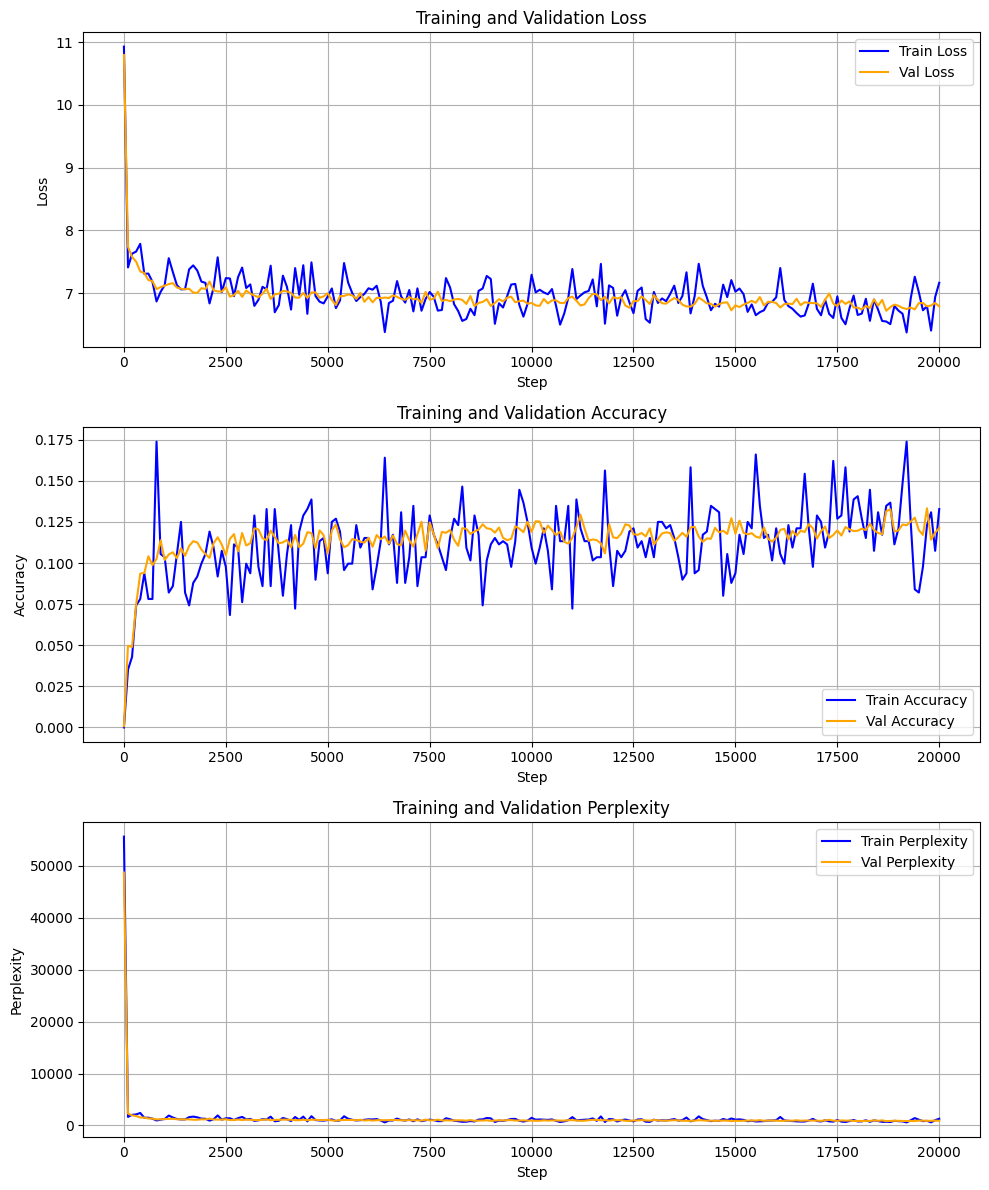

Plot saved as 'bitnet_training_curves.png'
Training completed.


In [ ]:
train()